# 03 · Alertes de dépose — FD001

**Question métier :** quels moteurs faut-il planifier pour une dépose dans les **30 prochains vols** ?

Le notebook 02 donne un nombre de vols restants. Mais un ingénieur de support client ne lit pas 100 nombres chaque matin : il a besoin d'une **liste de moteurs à traiter**. On passe donc d'une prédiction (« il lui reste 27 vols ») à une **décision** (« alerte : planifier la dépose »).

**Le cahier des charges vient de Safran** (Bastard et al., 2016 [10]) :
- **moins de 5 % de fausses alertes** : sur 100 alertes envoyées, moins de 5 ne correspondent à rien de réel ;
- **au moins 80 % de détection** : sur 100 moteurs qui doivent être déposés, au moins 80 sont signalés.

| # | Étape |
|---|---|
| 1 | Préparer les données et le modèle du notebook 02 |
| 2 | Obtenir des prédictions « honnêtes » sur le train (validation par moteur) |
| 3 | Savoir mesurer une alerte : précision, rappel, matrice de confusion |
| 4 | Règle n°1 : un seuil sur la prédiction centrale |
| 5 | Un modèle dédié aux alertes ferait-il mieux ? |
| 6 | Règle n°2 : exiger deux vols de suite (persistance) |
| 7 | Règle n°3 : un filet de sécurité sur la borne basse |
| 8 | Vue moteur : combien de vols d'avance a-t-on ? |
| 9 | Le verdict sur le test officiel |
| 10 | Statut de la flotte et export Power BI |

---
## Étape 1 · Préparer les données et le modèle

Les fonctions qui fabriquent les variables (notebook 02, étape 1) ont été déplacées dans `src/features.py`. On les **réutilise** au lieu de les recopier : une seule source de vérité. La vérification qui suit prouve que ce déplacement n'a rien changé.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import GroupKFold, cross_val_predict

sys.path.append(str(Path.cwd().parent))
from src.data_loader import FIG_DIR, POWERBI_DIR, PROCESSED_DIR, PROJECT_ROOT
from src.features import construire_variables

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

HORIZON = 30  # on veut être prévenu quand un moteur a 30 vols ou moins devant lui

train = pd.read_csv(PROCESSED_DIR / "train_FD001.csv")
test = pd.read_csv(PROCESSED_DIR / "test_FD001.csv")
capteurs = pd.read_csv(PROCESSED_DIR / "capteurs_retenus.csv")["capteur"].tolist()

sauvegarde = joblib.load(PROJECT_ROOT / "outputs" / "models" / "gbm_rul_FD001.joblib")
modele = sauvegarde["modele"]
VARIABLES = sauvegarde["variables"]
AJUSTEMENT = sauvegarde["ajustement_fourchette"]

train_f = construire_variables(train, capteurs)
test_f = construire_variables(test, capteurs)
print(f"Train : {train_f.shape}, test : {test_f.shape}, {len(VARIABLES)} variables")

Train : (20631, 52), test : (13096, 52), 48 variables


In [2]:
# ✅ Vérification : avec src/features.py, le modèle redonne exactement les prédictions du notebook 02
dernier_vol = test_f.groupby("unit").tail(1)
pred = np.clip(modele.predict(dernier_vol[VARIABLES]), 0, 125).round(1)
attendu = pd.read_csv(PROCESSED_DIR / "predictions_test_FD001.csv")["rul_predite"].values
assert np.allclose(pred, attendu), "Les variables ne sont plus calculées comme dans le notebook 02"
print("OK ✅ mêmes prédictions qu'au notebook 02")

OK ✅ mêmes prédictions qu'au notebook 02


---
## Étape 2 · Des prédictions « honnêtes » sur le train

Pour régler une règle d'alerte (quel seuil ? combien de vols de suite ?), il faut des prédictions sur des moteurs dont on connaît la vraie fin de vie. Ce sont ceux du train.

**Mais attention :** le modèle sauvegardé a été entraîné sur ces 100 moteurs. Ses prédictions sur eux seraient trop bonnes, puisqu'il les a « vus ». Il faut donc les prédictions de la **validation par moteur** du notebook 02 : chaque moteur est prédit par un modèle entraîné **sans lui**. On obtient ainsi, pour chaque vol de chaque moteur, ce qu'aurait dit le système en service.

Le notebook 02 les a sauvegardées (`predictions_validation_FD001.csv`), avec deux prédictions par vol, toutes deux nécessaires pour les règles d'alerte :
- la **prédiction centrale** ;
- la **borne basse** de la fourchette (quantile 10 %, ajustée, jamais au-dessus de la prédiction centrale).

On les relit au lieu de refaire la validation croisée : même résultat, quelques secondes de gagnées, et surtout **une seule source de vérité** pour les notebooks 03, 04 et 05.

In [3]:
val = pd.read_csv(PROCESSED_DIR / "predictions_validation_FD001.csv", float_precision="round_trip")
assert val[["unit", "cycle"]].equals(train_f[["unit", "cycle"]]), (
    "lignes dans un autre ordre que train_f"
)
# La vérité : ce moteur devait-il être déposé dans les 30 vols ?
val["a_deposer"] = val["RUL"] <= HORIZON

print(
    f"{len(val):,} vols, dont {val['a_deposer'].mean():.0%} à moins de {HORIZON} vols de la panne"
)
val.sample(3, random_state=0)

20,631 vols, dont 15% à moins de 30 vols de la panne


,unit,cycle,RUL,rul_predite,rul_basse,a_deposer
13474,68,43,156,124.879163,122.466706,False
1884,9,172,29,35.272730,29.507201,True
17170,85,19,169,119.968996,104.522619,False


---
## Étape 3 · Savoir mesurer une alerte

Une alerte peut avoir 4 issues. On les range dans la **matrice de confusion** :

|  | Le moteur devait être déposé (≤ 30 vols) | Le moteur pouvait attendre (> 30 vols) |
|---|---|---|
| **Alerte** | ✅ Vrai positif (VP) | ⚠️ Faux positif (FP) |
| **Pas d'alerte** | ❌ Faux négatif (FN), **le plus grave** | ✅ Vrai négatif (VN) |

Deux taux en découlent, qui correspondent exactement aux deux critères de Safran :
- **Précision** = VP / (VP + FP) : « quand j'alerte, ai-je raison ? ». Safran veut ≥ 95 % (donc < 5 % de fausses alertes).
- **Rappel (ou détection)** = VP / (VP + FN) : « parmi les moteurs à déposer, combien ai-je signalés ? ». Safran veut ≥ 80 %.

**Le dilemme :** si on alerte plus large, on rate moins de moteurs (le rappel monte), mais on alerte plus souvent pour rien (la précision baisse). Il n'existe pas de réglage parfait, seulement un **compromis à choisir**.

**Une nuance métier importante.** Une « fausse » alerte sur un moteur à 35 vols n'a rien à voir avec une fausse alerte sur un moteur à 120 vols : le premier sera déposé bientôt de toute façon. On distingue donc trois types d'alertes, en reprenant les zones du notebook 02 :
- **juste** : moteur à ≤ 30 vols ;
- **anticipée** : moteur à 31-60 vols (« à surveiller ») ; elle est un peu tôt, mais pas absurde ;
- **fausse** : moteur à > 60 vols, sain. C'est une vraie erreur, qui fait perdre du temps et de la confiance.

In [4]:
def evaluer_alertes(alerte, rul_vraie, horizon=HORIZON):
    """Mesure une règle d'alerte. alerte : booléens ; rul_vraie : vols restants réels."""
    alerte = np.asarray(alerte, dtype=bool)
    rul_vraie = np.asarray(rul_vraie)
    a_deposer = rul_vraie <= horizon
    vp = int(np.sum(alerte & a_deposer))
    fp = int(np.sum(alerte & ~a_deposer))
    fn = int(np.sum(~alerte & a_deposer))
    n_alertes = max(int(alerte.sum()), 1)
    return {
        "précision": vp / max(vp + fp, 1),
        "rappel": vp / max(vp + fn, 1),
        "alertes anticipées (31-60)": np.sum(alerte & (rul_vraie > horizon) & (rul_vraie <= 60))
        / n_alertes,
        "fausses alertes (>60)": np.sum(alerte & (rul_vraie > 60)) / n_alertes,
        "VP": vp,
        "FP": fp,
        "FN": fn,
    }


# ✅ Vérification sur un mini-exemple calculable de tête :
#    4 vols, vraies RUL [10, 20, 45, 90], alertes [oui, non, oui, oui]
#    -> VP=1 (10), FN=1 (20), FP=2 (45 et 90) ; précision 1/3, rappel 1/2 ; 1 anticipée et 1 fausse sur 3 alertes
r = evaluer_alertes([True, False, True, True], [10, 20, 45, 90])
assert (r["VP"], r["FN"], r["FP"]) == (1, 1, 2)
assert np.isclose(r["précision"], 1 / 3) and np.isclose(r["rappel"], 1 / 2)
assert np.isclose(r["alertes anticipées (31-60)"], 1 / 3) and np.isclose(
    r["fausses alertes (>60)"], 1 / 3
)
print("OK ✅ la fonction de mesure donne les bons chiffres sur l'exemple")

OK ✅ la fonction de mesure donne les bons chiffres sur l'exemple


---
## Étape 4 · Règle n°1 : un seuil sur la prédiction centrale

La règle la plus simple : **alerte si le modèle prédit ≤ S vols restants**. On essaie plusieurs seuils S.

Intuition : avec S = 30, on alerte pile au bon moment *si le modèle ne se trompe pas*. Avec S = 35, on se donne de la marge. Avec S = 25, on n'alerte que quand on est sûr.

In [5]:
def tableau(regles):
    """regles : {nom: tableau de booléens}. Renvoie les mesures de chaque règle, en %."""
    t = pd.DataFrame({nom: evaluer_alertes(a, val["RUL"]) for nom, a in regles.items()}).T
    pourcents = ["précision", "rappel", "alertes anticipées (31-60)", "fausses alertes (>60)"]
    t[pourcents] = (t[pourcents].astype(float) * 100).round(1)
    return t


seuils = [20, 25, 30, 35, 40]
tableau({f"prédiction ≤ {s}": val["rul_predite"] <= s for s in seuils})

,précision,rappel,alertes anticipées (31-60),fausses alertes (>60),VP,FP,FN
prédiction ≤ 20,98.9,62.4,1.1,0.0,1934.0,22.0,1166.0
prédiction ≤ 25,96.3,74.0,3.7,0.0,2293.0,87.0,807.0
prédiction ≤ 30,92.2,85.0,7.7,0.0,2636.0,222.0,464.0
prédiction ≤ 35,85.6,92.5,14.2,0.2,2867.0,484.0,233.0
prédiction ≤ 40,77.5,97.1,21.5,1.0,3009.0,874.0,91.0


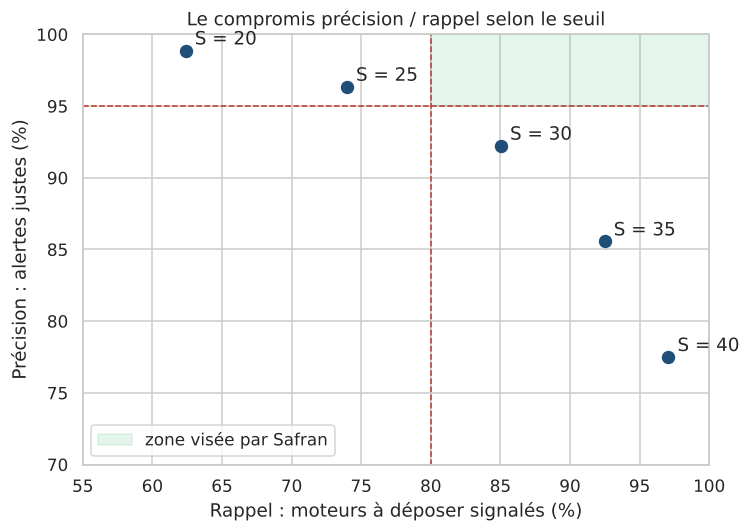

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
for s in seuils:
    r = evaluer_alertes(val["rul_predite"] <= s, val["RUL"])
    ax.scatter(r["rappel"] * 100, r["précision"] * 100, s=60, color="#1f4e79")
    ax.annotate(
        f"S = {s}",
        (r["rappel"] * 100, r["précision"] * 100),
        xytext=(6, 4),
        textcoords="offset points",
    )
ax.axhline(95, color="#c0392b", ls="--", lw=1)
ax.axvline(80, color="#c0392b", ls="--", lw=1)
ax.fill_between([80, 100], 95, 100, color="#27ae60", alpha=0.12, label="zone visée par Safran")
ax.set(
    xlim=(55, 100),
    ylim=(70, 100),
    xlabel="Rappel : moteurs à déposer signalés (%)",
    ylabel="Précision : alertes justes (%)",
    title="Le compromis précision / rappel selon le seuil",
)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "12_compromis_seuil.png")
plt.show()

> **Lecture :**
> - **Aucun seuil n'entre dans la zone verte.** S = 25 donne une bonne précision mais rate un quart des moteurs ; S = 30 détecte bien mais n'a « que » 92 % de précision.
> - **Mais regarde la colonne « fausses alertes (> 60) » : elle vaut 0 % jusqu'à S = 30.** Les alertes « en trop » portent toutes sur des moteurs à 31-60 vols, déjà proches de la dépose. Au sens métier (« ne pas déranger pour un moteur sain »), le critère des 5 % est largement tenu.
>
> On retient **S = 30** comme base (le meilleur rappel sans aucune fausse alerte sur moteur sain), et on va chercher à améliorer la précision stricte.

---
## Étape 5 · Un modèle dédié aux alertes ferait-il mieux ?

Idée naturelle : au lieu de mettre un seuil sur une prédiction de RUL, entraîner un **classifieur** qui répond directement à « ce moteur est-il à ≤ 30 vols ? », avec une probabilité.

Pour comparer les deux approches **sans dépendre d'un seuil**, on utilise la **précision moyenne** (*average precision*) : elle résume toute la courbe précision-rappel en un seul chiffre entre 0 et 1, plus haut = mieux.

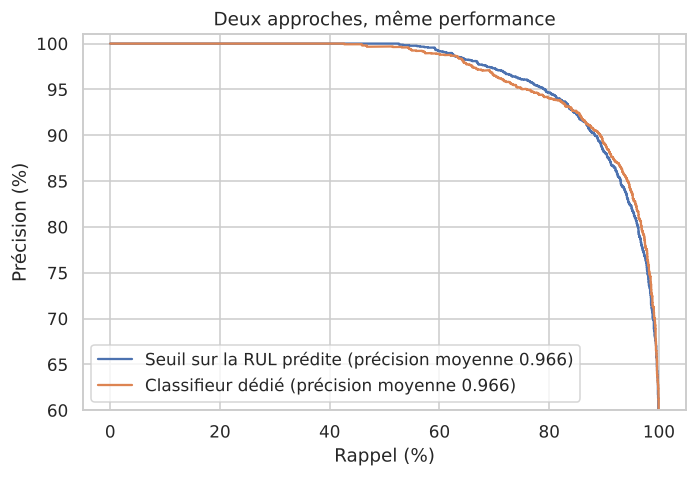

In [7]:
moteurs = train_f["unit"]
par_moteur = GroupKFold(n_splits=5)
classifieur = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, max_leaf_nodes=15, random_state=0
)
proba = cross_val_predict(
    classifieur,
    train_f[VARIABLES],
    val["a_deposer"],
    cv=par_moteur,
    groups=moteurs,
    method="predict_proba",
)[:, 1]  # colonne 1 = probabilité d'être "à déposer"

# Pour la régression, "plus la RUL prédite est basse, plus le moteur est à risque" : on passe donc -RUL
ap_regression = average_precision_score(val["a_deposer"], -val["rul_predite"])
ap_classifieur = average_precision_score(val["a_deposer"], proba)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for nom, score, ap in [
    ("Seuil sur la RUL prédite", -val["rul_predite"], ap_regression),
    ("Classifieur dédié", proba, ap_classifieur),
]:
    p, r, _ = precision_recall_curve(val["a_deposer"], score)
    ax.plot(r * 100, p * 100, label=f"{nom} (précision moyenne {ap:.3f})")
ax.set(
    xlabel="Rappel (%)",
    ylabel="Précision (%)",
    ylim=(60, 101),
    title="Deux approches, même performance",
)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "13_regression_vs_classifieur.png")
plt.show()

> **Lecture :** les deux courbes sont pratiquement superposées (précision moyenne identique à 0,001 près). Le classifieur n'apporte rien.
>
> **Choix : on garde le seuil sur la RUL.** Un seul modèle à maintenir au lieu de deux, et une règle que tout le monde comprend (« on alerte quand il reste 30 vols »). Une probabilité de 0,73 est beaucoup plus dure à expliquer. **À performance égale, on choisit le plus simple.**

---
## Étape 6 · Règle n°2 : exiger deux vols de suite

**Le problème :** une prédiction peut passer sous le seuil un vol, puis remonter au vol suivant à cause du bruit. L'alerte s'allume, s'éteint, se rallume… Les opérateurs finissent par ne plus y croire. C'est le problème classique des systèmes d'alerte.

**La solution, standard en surveillance industrielle :** n'alerter que si la condition est vraie **k vols de suite**. On compare k = 1, 2, 3, et on compte les **extinctions** : combien de fois une alerte allumée s'est éteinte au vol suivant.

In [8]:
def persistance(condition, k, groupes):
    """Vrai seulement si `condition` est vraie sur les k derniers vols du même moteur."""
    c = pd.Series(np.asarray(condition, dtype=int), index=groupes.index)
    somme = c.groupby(groupes).transform(lambda x: x.rolling(k, min_periods=k).sum())
    return (somme >= k).values


def extinctions(alerte, groupes):
    """Nombre de fois où une alerte allumée s'éteint au vol suivant (même moteur)."""
    a = pd.Series(np.asarray(alerte, dtype=int), index=groupes.index)
    return int((a.groupby(groupes).diff() == -1).sum())


# ✅ Vérification sur un moteur fictif : prédictions 40, 29, 31, 28, 27 (seuil 30)
#    condition : non, oui, non, oui, oui -> avec k=2, alerte seulement au dernier vol
f = pd.Series([1, 1, 1, 1, 1])
assert list(persistance(np.array([40, 29, 31, 28, 27]) <= 30, 2, f)) == [
    False,
    False,
    False,
    False,
    True,
]
assert extinctions([False, True, False, True, True], f) == 1
print("OK ✅ persistance et extinctions vérifiées sur l'exemple")

sous_seuil = val["rul_predite"] <= 30
regles = {
    f"seuil 30 · {k} vol(s) de suite": persistance(sous_seuil, k, val["unit"]) for k in [1, 2, 3]
}
t = tableau(regles)
t["extinctions"] = [extinctions(a, val["unit"]) for a in regles.values()]
t

OK ✅ persistance et extinctions vérifiées sur l'exemple


,précision,rappel,alertes anticipées (31-60),fausses alertes (>60),VP,FP,FN,extinctions
seuil 30 · 1 vol(s) de suite,92.2,85.0,7.7,0.0,2636.0,222.0,464.0,68
seuil 30 · 2 vol(s) de suite,94.1,81.7,5.9,0.0,2532.0,158.0,568.0,32
seuil 30 · 3 vol(s) de suite,95.2,78.6,4.8,0.0,2436.0,122.0,664.0,22


> **Lecture :** passer de 1 à 2 vols de suite **divise par deux les extinctions** et fait gagner 2 points de précision, pour 3 points de rappel. Passer à 3 vols réduit encore les extinctions (d'un tiers environ), mais le rappel passe sous les 80 % de Safran.
>
> **Choix : 2 vols de suite.** Coût : l'alerte arrive en moyenne un vol plus tard, ce qui est négligeable avec 30 vols d'horizon.

---
## Étape 7 · Règle n°3 : un filet de sécurité

**Le problème :** au notebook 02, on a vu que près de la panne, le modèle annonce en moyenne quelques vols **de trop** (biais « trop tard »). Un moteur à 20 vols peut être prédit à 35, et passer sous le radar.

**L'idée :** ajouter une deuxième condition, qui utilise la **borne basse** de la fourchette : « même si la prédiction centrale est rassurante, si le scénario pessimiste descend sous L vols, on alerte ». C'est exactement le rôle de la borne basse annoncé au notebook 02.

**Règle complète :**
> 🔴 **Alerte** si la prédiction centrale est ≤ 30 vols **deux vols de suite**, **OU** si la borne basse est ≤ L vols.

On essaie plusieurs valeurs de L, toujours en validation.

In [9]:
base = persistance(val["rul_predite"] <= 30, 2, val["unit"])
regles = {"sans filet": base}
for L in [15, 20, 25]:
    regles[f"+ filet borne basse ≤ {L}"] = base | (val["rul_basse"] <= L).values  # | veut dire OU
tableau(regles)

,précision,rappel,alertes anticipées (31-60),fausses alertes (>60),VP,FP,FN
sans filet,94.1,81.7,5.9,0.0,2532.0,158.0,568.0
+ filet borne basse ≤ 15,94.1,81.8,5.9,0.0,2537.0,158.0,563.0
+ filet borne basse ≤ 20,92.1,85.0,7.9,0.0,2636.0,226.0,464.0
+ filet borne basse ≤ 25,83.5,91.8,16.1,0.4,2845.0,561.0,255.0


In [10]:
# Où sont les moteurs ratés ? Rappel par tranche de vols restants réels
tranches = pd.cut(val["RUL"], bins=[-1, 10, 20, 25, 30], labels=["0-10", "11-20", "21-25", "26-30"])
critique = val["a_deposer"].values
rappel_tranche = pd.DataFrame(
    {
        nom: pd.Series(a[critique]).groupby(tranches[critique].values, observed=True).mean()
        for nom, a in regles.items()
    }
)
(rappel_tranche * 100).round(0)

,sans filet,+ filet borne basse ≤ 15,+ filet borne basse ≤ 20,+ filet borne basse ≤ 25
0-10,100.0,100.0,100.0,100.0
11-20,93.0,93.0,96.0,99.0
21-25,64.0,64.0,70.0,87.0
26-30,36.0,36.0,45.0,63.0


> **Lecture :**
> - **Sans filet, à 0-10 vols de la panne, 100 % des cas sont signalés.** Les ratés sont tous au début de la fenêtre (21-30 vols), où le moteur sera rattrapé quelques vols plus tard.
> - **Le filet L = 15 ne sert à rien** (la règle de base couvre déjà ces cas).
> - **Le filet L = 20 gagne 3 points de rappel** (85 %, au-dessus des 80 % de Safran), répartis sur toute la fenêtre de 11 à 30 vols. Il ne crée toujours **quasiment aucune fausse alerte sur moteur sain** (moins de 1 %).
> - **Le filet L = 25 gagne encore en rappel, mais 16 % des alertes portent alors sur des moteurs à plus de 30 vols.** Ça commence à faire beaucoup de bruit pour les équipes.
>
> **Choix : L = 20.** C'est le réglage qui privilégie la sécurité (rater une dépose est l'erreur la plus grave, cf. le score asymétrique de la NASA) sans inonder les opérateurs.
>
> **Le bilan face à Safran, en validation :** rappel de 85 % (objectif ≥ 80 % : ✅) ; moins de 1 % d'alertes sur des moteurs sains (✅ au sens métier). Au sens strict (toute alerte sur un moteur à plus de 30 vols), la précision est de 92 %, sous les 95 %. **C'est un choix assumé**, détaillé dans la synthèse.

In [11]:
L_FILET = 20
SEUIL = 30
K_VOLS = 2


def regle_alerte(df):
    """Règle retenue. df : une ligne par vol, avec unit, rul_predite, rul_basse.
    Renvoie (alerte, motif) pour chaque ligne."""
    tendance = persistance(df["rul_predite"] <= SEUIL, K_VOLS, df["unit"])
    filet = (df["rul_basse"] <= L_FILET).values
    motif = np.select(
        [tendance, filet],
        [
            f"prédiction ≤ {SEUIL} vols ({K_VOLS} vols de suite)",
            f"scénario pessimiste ≤ {L_FILET} vols",
        ],
        default="",
    )
    return tendance | filet, motif


val["alerte"], val["motif"] = regle_alerte(val)
bilan_validation = evaluer_alertes(val["alerte"], val["RUL"])
pd.Series(bilan_validation).round(3)

précision                        0.921
rappel                           0.850
alertes anticipées (31-60)       0.079
fausses alertes (>60)            0.000
VP                            2636.000
FP                             226.000
FN                             464.000
dtype: float64

---
## Étape 8 · Vue moteur : combien de vols d'avance ?

Les taux ci-dessus comptent des **vols**. Mais le décideur raisonne en **moteurs** : « chaque moteur est-il signalé à temps pour organiser sa dépose ? ».

Pour chacun des 100 moteurs du train, on regarde **à combien de vols de la panne l'alerte s'est déclenchée pour la première fois**. C'est l'**anticipation** : le temps laissé à la logistique pour commander les pièces et réserver un créneau d'atelier.

Moteurs signalés avant leur panne : 100 / 100
Anticipation : minimum 15 vols, médiane 27, maximum 52
Moteurs signalés à moins de 10 vols de la panne : 0
Moteurs signalés à plus de 60 vols de la panne : 0


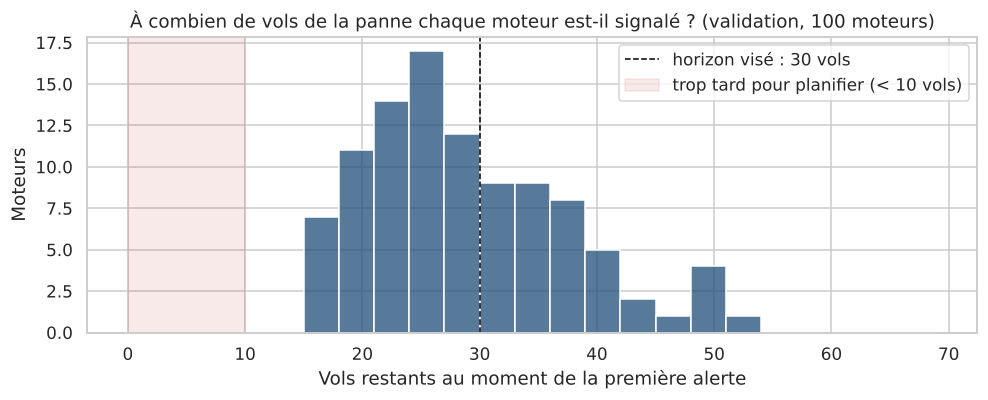

In [12]:
premiere_alerte = val[val["alerte"]].sort_values("cycle").groupby("unit")["RUL"].first()
moteurs_alertes = premiere_alerte.size

print(f"Moteurs signalés avant leur panne : {moteurs_alertes} / {val['unit'].nunique()}")
print(
    f"Anticipation : minimum {premiere_alerte.min()} vols, médiane {premiere_alerte.median():.0f}, maximum {premiere_alerte.max()}"
)
print(f"Moteurs signalés à moins de 10 vols de la panne : {(premiere_alerte < 10).sum()}")
print(f"Moteurs signalés à plus de 60 vols de la panne : {(premiere_alerte > 60).sum()}")

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(premiere_alerte, bins=range(0, 70, 3), color="#1f4e79", ax=ax)
ax.axvline(HORIZON, color="black", ls="--", lw=1, label=f"horizon visé : {HORIZON} vols")
ax.axvspan(0, 10, color="#c0392b", alpha=0.1, label="trop tard pour planifier (< 10 vols)")
ax.set(
    title="À combien de vols de la panne chaque moteur est-il signalé ? (validation, 100 moteurs)",
    xlabel="Vols restants au moment de la première alerte",
    ylabel="Moteurs",
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "14_anticipation_alertes.png")
plt.show()

> **Lecture :** **les 100 moteurs sont signalés**, aucun à moins de 10 vols de sa panne. L'anticipation médiane est proche de l'horizon visé de 30 vols. C'est la vraie bonne nouvelle : les ratés de l'étape 7 sont des moteurs signalés **un peu plus tard** que l'idéal, pas des moteurs oubliés.

---
## Étape 9 · Le verdict sur le test officiel

On applique la règle, réglée uniquement en validation, aux 100 moteurs du test.

- Le modèle central est celui du notebook 02.
- Le modèle de la borne basse (quantile 10 %) est lui aussi celui du notebook 02, relu dans la même sauvegarde.
- On prédit **tous les vols** du test, pas seulement le dernier, parce que la règle « 2 vols de suite » a besoin du vol précédent.

**Limite à garder en tête :** le test est une **photo** à un instant donné. On ne peut mesurer que « au dernier vol observé, le moteur était-il signalé ? », pas l'anticipation, puisque la suite de sa vie n'est pas fournie. Et seuls 25 moteurs sont à ≤ 30 vols : **chaque moteur raté pèse 4 points de rappel**.

In [13]:
modele_bas = sauvegarde["modele_q10"]

flotte = test_f[["unit", "cycle", "RUL"]].copy()
flotte["rul_predite"] = np.clip(modele.predict(test_f[VARIABLES]), 0, 125)
flotte["rul_basse"] = np.clip(modele_bas.predict(test_f[VARIABLES]) - AJUSTEMENT, 0, 125)
flotte["rul_basse"] = np.minimum(flotte["rul_basse"], flotte["rul_predite"])
flotte["alerte"], flotte["motif"] = regle_alerte(flotte)

photo = flotte.groupby("unit").tail(1).set_index("unit")  # l'état de la flotte "aujourd'hui"
bilan_test = evaluer_alertes(photo["alerte"], photo["RUL"])

matrice = pd.crosstab(
    photo["alerte"].map({True: "Alerte", False: "Pas d'alerte"}),
    (photo["RUL"] <= HORIZON).map({True: "À déposer (≤ 30)", False: "Peut attendre (> 30)"}),
)
display(matrice)
print(
    f"Précision {bilan_test['précision']:.0%} · rappel {bilan_test['rappel']:.0%} · "
    f"fausses alertes sur moteur sain {bilan_test['fausses alertes (>60)']:.0%}"
)

RUL,Peut attendre (> 30),À déposer (≤ 30)
alerte,,
Alerte,1,19
Pas d'alerte,74,6


Précision 95% · rappel 76% · fausses alertes sur moteur sain 0%


In [14]:
# ✅ Vérification : la matrice compte bien 100 moteurs, et la précision se retrouve à la main
assert matrice.values.sum() == 100
vp = matrice.loc["Alerte", "À déposer (≤ 30)"]
assert np.isclose(bilan_test["précision"], vp / matrice.loc["Alerte"].sum())
print("OK ✅ matrice de confusion cohérente")

rates = photo[(photo["RUL"] <= HORIZON) & ~photo["alerte"]]
print(f"\nMoteurs à déposer non signalés au dernier vol ({len(rates)}) :")
rates[["RUL", "rul_predite", "rul_basse"]].round(0).sort_values("RUL")

OK ✅ matrice de confusion cohérente

Moteurs à déposer non signalés au dernier vol (6) :


,RUL,rul_predite,rul_basse
unit,,,
41,18,30.0,28.0
37,21,36.0,24.0
53,26,31.0,27.0
18,28,35.0,26.0
40,28,40.0,23.0
52,29,40.0,24.0


> **Lecture honnête :**
> - **Précision : 19 alertes justes sur 20 (95 %, pile l'objectif strict de Safran).** La seule alerte « en trop » porte sur un moteur à 38 vols : c'est une alerte anticipée. **Aucune fausse alerte sur un moteur sain.**
> - **Rappel : 19 moteurs sur 25 signalés (76 %)**, un peu sous les 85 % de la validation et sous l'objectif de 80 %. Avec 25 moteurs, un seul moteur d'écart fait passer de 76 % à 80 %, donc l'écart avec la validation est dans la marge de hasard d'un si petit échantillon.
> - **Les moteurs non signalés sont à 18-29 vols réels**, et le modèle les voyait à 30-40. Ce sont des moteurs en début de fenêtre. En validation, ce profil était rattrapé dans les vols suivants, toujours à plus de 10 vols de la panne. Deux d'entre eux (18 et 21 vols) méritent l'attention : c'est le type d'erreur à surveiller en exploitation.

---
## Étape 10 · Statut de la flotte et export Power BI

On classe chaque moteur en service dans un **statut** compréhensible par tous :

| Statut | Règle | Action |
|---|---|---|
| 🔴 **Alerte** | la règle d'alerte se déclenche | planifier la dépose, déclencher la commande de pièces |
| 🟠 **Surveillance** | pas d'alerte, mais prédiction ≤ 60 vols | suivre de près, préparer |
| 🟢 **RAS** | le reste | rien à faire |

Dans le CSV, on met des libellés en texte simple. Les couleurs se mettront dans Power BI.

In [15]:
photo["statut"] = np.select(
    [photo["alerte"], photo["rul_predite"] <= 60], ["Alerte", "Surveillance"], default="RAS"
)

repartition = photo["statut"].value_counts().reindex(["Alerte", "Surveillance", "RAS"])
print(repartition.to_string())

export = pd.DataFrame(
    {
        "id_moteur": [f"TEST-{u:03d}" for u in photo.index],
        "statut": photo["statut"].values,
        "motif_alerte": photo["motif"].values,
        "rul_predite": photo["rul_predite"].round(1).values,
        "rul_basse_80": photo["rul_basse"].round(1).values,
        "rul_reelle": photo["RUL"].values,
    }
)
export.to_csv(PROCESSED_DIR / "alertes_test_FD001.csv", index=False)
export.to_csv(POWERBI_DIR / "fact_alertes.csv", index=False, sep=";", decimal=",")
joblib.dump(
    {
        "modele_bas": modele_bas,
        "seuil": SEUIL,
        "k_vols": K_VOLS,
        "l_filet": L_FILET,
        "horizon": HORIZON,
    },
    PROJECT_ROOT / "outputs" / "models" / "regle_alerte_FD001.joblib",
)
export[export["statut"] == "Alerte"].sort_values("rul_predite").head(10)

statut
Alerte          20
Surveillance    18
RAS             62


,id_moteur,statut,motif_alerte,rul_predite,rul_basse_80,rul_reelle
80,TEST-081,Alerte,prédiction ≤ 30 vols (2 vols de suite),5.0,3.1,8
75,TEST-076,Alerte,prédiction ≤ 30 vols (2 vols de suite),6.1,4.3,10
33,TEST-034,Alerte,prédiction ≤ 30 vols (2 vols de suite),6.8,5.5,7
67,TEST-068,Alerte,prédiction ≤ 30 vols (2 vols de suite),6.9,5.3,8
81,TEST-082,Alerte,prédiction ≤ 30 vols (2 vols de suite),7.3,6.7,9
30,TEST-031,Alerte,prédiction ≤ 30 vols (2 vols de suite),11.0,8.1,8
34,TEST-035,Alerte,prédiction ≤ 30 vols (2 vols de suite),11.5,6.0,11
41,TEST-042,Alerte,prédiction ≤ 30 vols (2 vols de suite),12.3,8.9,10
48,TEST-049,Alerte,prédiction ≤ 30 vols (2 vols de suite),12.4,9.3,21
19,TEST-020,Alerte,prédiction ≤ 30 vols (2 vols de suite),12.9,9.3,16


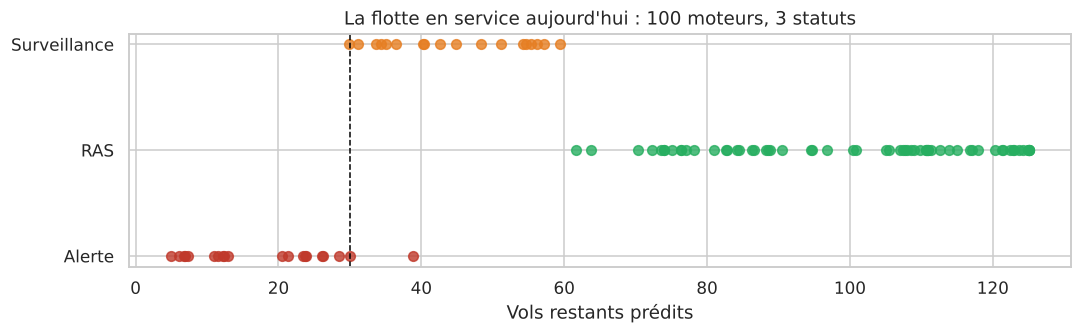

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.2))
couleurs = {"Alerte": "#c0392b", "Surveillance": "#e67e22", "RAS": "#27ae60"}
for statut, groupe in photo.groupby("statut"):
    ax.scatter(
        groupe["rul_predite"], [statut] * len(groupe), color=couleurs[statut], s=40, alpha=0.8
    )
ax.axvline(SEUIL, color="black", ls="--", lw=1)
ax.set(
    xlabel="Vols restants prédits",
    title="La flotte en service aujourd'hui : 100 moteurs, 3 statuts",
)
plt.tight_layout()
plt.savefig(FIG_DIR / "15_statut_flotte.png")
plt.show()

> **Le filet de sécurité en action :** sur le test, 2 alertes viennent du filet. L'une concerne le moteur **TEST-036**, que le modèle central voyait **au-dessus de 30 vols** : sans le filet, il n'aurait pas été signalé. Il ne lui restait en réalité que **19 vols**. La colonne `motif_alerte` du fichier explique chaque alerte moteur par moteur, ce qui est indispensable pour qu'un ingénieur fasse confiance au système.

## Synthèse pour le décideur

1. **On passe d'une prédiction à une décision**, avec une règle compréhensible : *alerte si le modèle prédit 30 vols ou moins deux vols de suite, ou si le scénario pessimiste descend sous 20 vols.*
2. **En validation sur 100 moteurs, tous sont signalés avant leur panne**, aucun à moins de 10 vols. L'anticipation médiane est proche des 30 vols visés : c'est le temps laissé à la logistique.
3. **Face aux critères Safran** [10] :
   - **détection : 85 %** en validation (objectif 80 % ✅), 76 % sur le petit test de 25 moteurs critiques ;
   - **alertes sur des moteurs sains : moins de 1 %** (objectif < 5 % ✅ au sens métier) ;
   - **au sens strict** (toute alerte sur un moteur à plus de 30 vols comptée comme fausse) : 92 % de précision en validation, 95 % sur le test. Les alertes « en trop » concernent toutes des moteurs à 31-60 vols, **déjà proches de la dépose**.
4. **Le réglage est un curseur, pas une vérité.** On a privilégié la sécurité (ne pas rater une dépose) plutôt que la précision stricte. Un décideur qui préfère moins d'alertes peut retirer le filet de sécurité : la précision stricte monte à 94 %, et le rappel descend à 82 %.
5. **Un classifieur dédié n'a rien apporté** : on garde un seul modèle, plus simple à maintenir et à expliquer.

**Étape suivante (notebook 04) :** utiliser ces alertes et les fourchettes de RUL pour piloter le **stock de pièces** (méthode de Rodrigues & Yoneyama [8]).